In [2]:
import os
from PIL import Image
import PIL

## Niveau 1

In [3]:
# 1- Une fonction qui prend le chemin du dossier images
# retourne la liste des chemins complets des images valides

def list_images_path(path_images):
    # Verifier que le chemin existe
    if not os.path.exists(path_images):
        raise FileNotFoundError(f"Le chemin {path_images} n'existe pas !")
    
    # Parcourir le dossier et vériifer que c'est des images
    images_path = []
    for idx, img in enumerate(os.listdir(path_images)):
        img_name_lower = img.lower()
        if img_name_lower.endswith(('jpg', 'png', 'jfif')): 
            images_path.append(os.path.join(path_images, img))
    return images_path
        
list_images_path('dataset/images/')
    

['dataset/images/img_001.JPG',
 'dataset/images/img_002.JPG',
 'dataset/images/img_003.JPG',
 'dataset/images/img_004.JPG']

In [4]:
# 2- Une fonction qui charge une image à partir d'un chemin
# retourne l'image sous forme PIL ou numpy
import numpy as np
def image_as_array(image_path):
    # Vérifier que l'image existe
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"L'image {image_path} n'existe pas!")
    
    # vérifier que c'est une image
    image_path_lower = image_path.lower()
    if not image_path_lower.endswith(('png', 'jpg', 'jfif')):
        raise PIL.UnidentifiedImageError(f"Le chemin {image_path} n'est pas une image valide !")
    
    # Convertir l'image en numpy array
    image_array = np.asanyarray(Image.open(image_path)) 
    return image_array


image_as_array('dataset/images/img_001.JPG')
    

array([[[155, 141, 158],
        [120, 106, 123],
        [ 31,  18,  35],
        ...,
        [159, 150, 169],
        [148, 139, 158],
        [149, 140, 159]],

       [[147, 133, 150],
        [126, 112, 129],
        [ 45,  32,  49],
        ...,
        [154, 145, 164],
        [169, 160, 179],
        [154, 145, 164]],

       [[152, 138, 155],
        [151, 137, 154],
        [ 80,  67,  84],
        ...,
        [130, 121, 140],
        [166, 157, 176],
        [167, 158, 177]],

       ...,

       [[164, 151, 171],
        [159, 146, 166],
        [157, 144, 164],
        ...,
        [201, 192, 209],
        [201, 192, 209],
        [200, 191, 208]],

       [[162, 149, 169],
        [159, 146, 166],
        [162, 149, 169],
        ...,
        [200, 191, 208],
        [199, 190, 207],
        [198, 189, 206]],

       [[174, 161, 181],
        [166, 153, 173],
        [161, 148, 168],
        ...,
        [198, 189, 206],
        [196, 187, 204],
        [195, 186, 203]]

In [5]:
# 3- Une fonction que charge toutes les images à partir d'une liste de chemins 
def list_Images(paths):

    images = []
    for path in paths:
        image = Image.open(path)
        images.append(image)
    return images


list_Images(
    [
        'dataset/images/img_001.JPG',
        'dataset/images/img_002.JPG'
    ]
)

[<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256>]

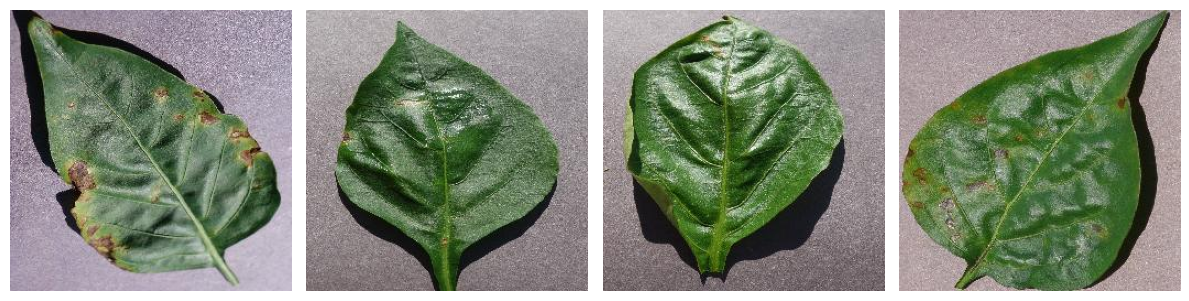

In [6]:
# 4- Fonction qui affiche n images sans labels
import matplotlib.pyplot as plt
def plot_images_NoLabel(paths):
    images = list_images_path(paths) # on récupére la liste des images
    
    fig, axes = plt.subplots(1, len(images), figsize= (12,6))
    for idx, image in enumerate (images):
        img = Image.open(image)
        axes[idx].imshow(img)
        axes[idx].axis('off')
    plt.tight_layout()
    plt.show()
        
plot_images_NoLabel('dataset/images/')

## Niveau 2

In [7]:
# 5- Une fonction qui charge le fichier labels.csv 
# retourne une structure exploitable(dict ou DataFrame)
import pandas as pd
def load_labels(file):
    labels = pd.read_csv(file, sep=';')
    return labels # return file as DataFrame

load_labels('labels.csv')

,image_id,label
0,img_001.jpg,cat
1,img_002.jpg,dog
2,img_004.jpg,dog
3,img_777.jpg,bird


In [8]:
# 6- Une fonction qui extrait l'ID de l'image à partir du nom du fichier
# ex: img_001.jpg → img_001

def extract_image_id(file):
    # charger le fichier avec la fonction 1
    file = load_labels(file)
    
    images_id = [] # pour stocker les ids de l'image
    for image in file['image_id']:
        image_id = image.strip().split('.')[0]
        images_id.append(image_id)
    return images_id

extract_image_id('labels.csv')

['img_001', 'img_002', 'img_004', 'img_777']

In [9]:
# 7- Une fonction qui :
# associe chaque image à son label
# sans supposer le même ordre
# sans supposer le même nombre
# retourne uniquement les paires valides


def images_with_labels(file, images):
    images_labels = dict() # dictionnaire pour stocker les paires clé: valeur 
    
    # récupérer les labels 
    labels = extract_image_id(file)
    
    # récupérer les images
    images = list_images_path(images)
    for img in images:
        img = img.strip().split('\\')[1].lower() 
        img_name = img.strip().split('.')[0]
        for label in labels :
            label = label.lower()
            if label == img_name:
                images_labels[label] = img
            
    return images_labels



images_with_labels('labels.csv', 'dataset/images')

{'img_001': 'img_001.jpg', 'img_002': 'img_002.jpg', 'img_004': 'img_004.jpg'}

## Niveau 3

In [46]:
# 8- Gérer les cas suivants:
# image sans label
# label sans image
# image corrompue
# extension invalide
def images_exceptions(file, images_pth):
    
    # 1- on charge les labels depuis le fichier .csv
    labels = extract_image_id(file) 
    # On rend le tout en minuscule pour uniformer les données
    labels = [item.lower() for item in labels]
    
    # 2 - On charge les images depuis le répertoire
    images = list_images_path(images_pth) 
    
    # 3- on crée une liste pour stocker les noms des images sans extension pour comparer avec les labels
    image_names = []
    
    # On crée une autre liste qui stocke les noms d'images avec extension
    image_names_extension = []
    
    
    # 4 - une boucle qui permet de récupérer le nom des images sans extension afin de les stocker dans la liste en haut
    for img in images:
        img = img.strip().split('\\')[1].lower()  
        img_name = img.strip().split('.')[0]  
        image_names.append(img_name)
        image_names_extension.append(img)
        
    
    # Cas 1: Image sans label
    for img in image_names:
        if img not in labels:
            print(f"The image {img} doesn't have a label")
        continue  
    # Cas 2: Label sans Image
    for i in range(len(labels)):
        if labels[i] not in image_names:
            print(f" The label {labels[i]} doesn't have an image")
        continue
    # Cas 3: Image corrompue
    for img in images:
        try:
            img = Image.open(img)
            img.verify()
        except (IOError, SyntaxError, ValueError, Image.DecompressionBombError) as e:
            print(f"L'image {img} est corrompue ! L'erreur est : {e}")
        continue
            
    # Cas 4: Image avec extension non valide
    for img in image_names_extension:
        if not img.endswith(('png', 'jpg', 'jfif')):
            print(f"Image {img} has a non valid extension")

        continue
            
        
images_exceptions('labels.csv', 'dataset/images')    

The image img_003 doesn't have a label
 The label img_777 doesn't have an image


In [73]:
#9- Une fonction qui retourn un rapport
# nombre d’images ignorées
# nombre de labels ignorés
# nombre de paires valides

def report(file, images_pth):
    
    # 1- on charge les labels depuis le fichier .csv
    labels = extract_image_id(file) 
    # On rend le tout en minuscule pour uniformer les données
    labels = [item.lower() for item in labels]
    
    # 2 - On charge les images depuis le répertoire
    images = list_images_path(images_pth) 
    
    # 3- on crée une liste pour stocker les noms des images sans extension pour comparer avec les labels
    image_names = []
    
    # On crée une autre liste qui stocke les noms d'images avec extension
    image_names_extension = []
    
    
    # Liste pour stocker les images ignorées, labels ignorée et les paires valides
    images_rep = []
    labels_rep = []
    image_label = dict()
    
    
    # 4 - une boucle qui permet de récupérer le nom des images sans extension afin de les stocker dans la liste en haut
    for img in images:
        img = img.strip().split('\\')[1].lower()  
        img_name = img.strip().split('.')[0]  
        image_names.append(img_name)
        image_names_extension.append(img)
        
    
    # Cas 1: Image sans label
    for img in image_names:
        if img not in labels:
            images_rep.append(img)
        continue  
    # Cas 2: Label sans Image
    for i in range(len(labels)):
        if labels[i] not in image_names:
            labels_rep.append(labels[i])
        continue
    # Cas 3: Image corrompue
    for img in images:
        try:
            img = Image.open(img)
            img.verify()
        except (IOError, SyntaxError, ValueError, Image.DecompressionBombError) as e:
            images_rep.append(img)
        continue
            
    # Cas 4: Image avec extension non valide
    for img in image_names_extension:
        if not img.endswith(('png', 'jpg', 'jfif')):
            images_rep.append(img)

        continue
    
    # Cas 5: Image valide avec extension
    
    m = len(image_names)
    for img in (image_names):
        idx = 0
        print("1--- ", img)
        while idx < m:
            if img == (labels[idx]):
                #image_label[labels[idx]] = img
                print(img== labels[idx])
                idx= idx+ 1
                print("idx+ 1 : ", idx)
                print("+++++++++++++++++++++++++++++++++++++++++++++++")
            
    print(f" Les images ignorées sont : {len(images_rep)}")
    print(f"Les labels ignorées sont : {len(labels_rep)}")
    print(f"Les paires images-labels valides sont : {image_label}")    
    
report('labels.csv', 'dataset/images')    

1---  img_001
True
idx+ 1 :  1
+++++++++++++++++++++++++++++++++++++++++++++++


KeyboardInterrupt: 

## Niveau 4


In [1]:
print("hello world")

hello world
